[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
/tmp/ipython-input-5-844723915.py:32: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train_df['keyword'].fillna('missing', inplace=True)
/tmp/ipython-input-5-844723915.py:33: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method

Initial data shape: (7613, 5)


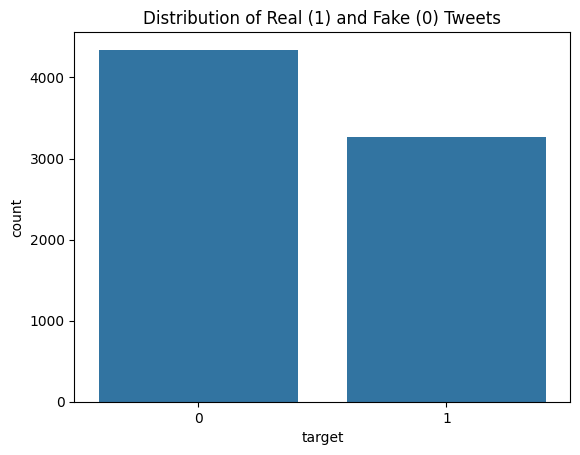

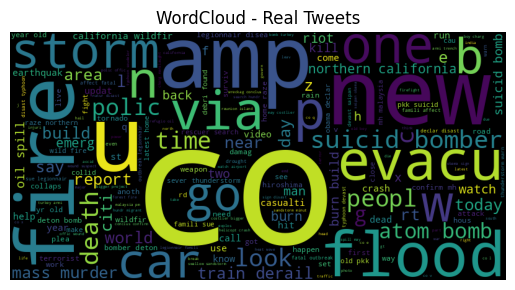

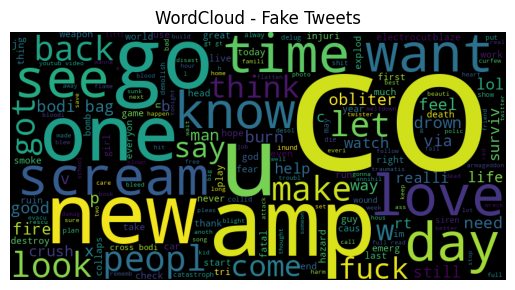


Logistic Regression Classification Report:

              precision    recall  f1-score   support

           0       0.79      0.88      0.83       874
           1       0.81      0.68      0.74       649

    accuracy                           0.80      1523
   macro avg       0.80      0.78      0.79      1523
weighted avg       0.80      0.80      0.79      1523



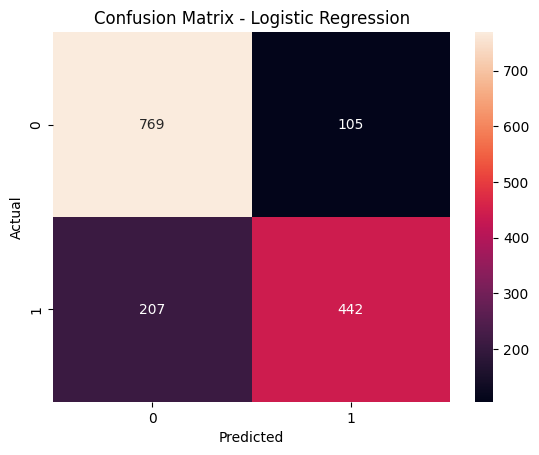


SVM Classification Report:

              precision    recall  f1-score   support

           0       0.79      0.89      0.84       874
           1       0.82      0.67      0.74       649

    accuracy                           0.80      1523
   macro avg       0.80      0.78      0.79      1523
weighted avg       0.80      0.80      0.79      1523



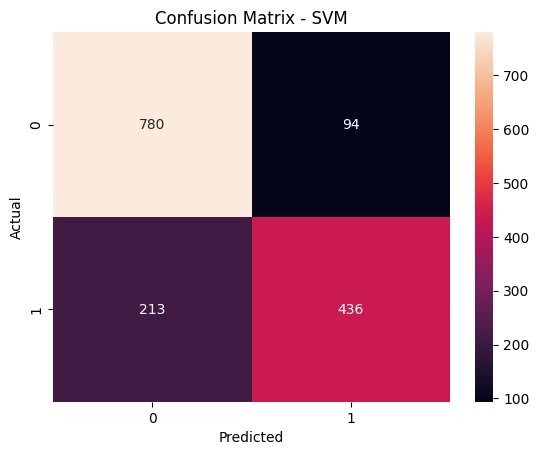


Naive Bayes Classification Report:

              precision    recall  f1-score   support

           0       0.79      0.89      0.84       874
           1       0.82      0.69      0.75       649

    accuracy                           0.80      1523
   macro avg       0.81      0.79      0.79      1523
weighted avg       0.80      0.80      0.80      1523



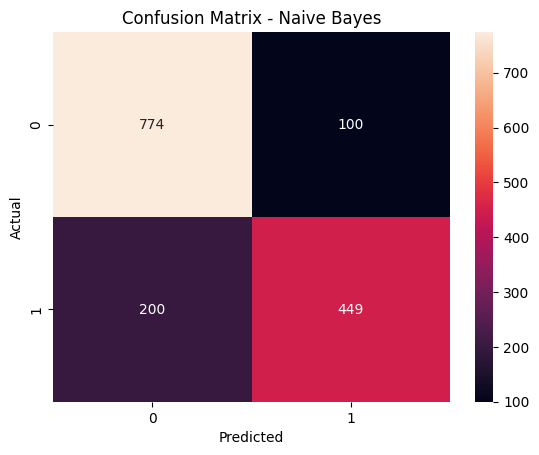

Best parameters for Logistic Regression: {'C': 1}
Final tuned Logistic Regression performance:
              precision    recall  f1-score   support

           0       0.79      0.88      0.83       874
           1       0.81      0.68      0.74       649

    accuracy                           0.80      1523
   macro avg       0.80      0.78      0.79      1523
weighted avg       0.80      0.80      0.79      1523



/tmp/ipython-input-5-844723915.py:104: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  test_df['keyword'].fillna('missing', inplace=True)
/tmp/ipython-input-5-844723915.py:105: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)'

submission.csv file created.
Vectorizer and model saved successfully.


In [5]:
# Fake News Detection on Twitter using NLP and ML (Without spaCy)

# Step 1: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import pickle
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix
from wordcloud import WordCloud

# Step 2: Download required NLTK resources
nltk.download('stopwords')
nltk.download('punkt')
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

# Step 3: Load Dataset
train_df = pd.read_csv('train.csv')
print("Initial data shape:", train_df.shape)

# Step 4: Data Cleaning
train_df['keyword'].fillna('missing', inplace=True)
train_df['location'].fillna('missing', inplace=True)
train_df.dropna(subset=['text'], inplace=True)

# Step 5: Preprocess Text
def clean_text(text):
    text = re.sub(r'[^a-zA-Z]', ' ', text.lower())
    tokens = [stemmer.stem(word) for word in text.split() if word not in stop_words]
    return " ".join(tokens)

train_df['clean_text'] = train_df['text'].apply(clean_text)

# Step 6: EDA - Class Distribution
sns.countplot(x='target', data=train_df)
plt.title('Distribution of Real (1) and Fake (0) Tweets')
plt.show()

# Step 7: WordClouds
real_text = ' '.join(train_df[train_df['target'] == 1]['clean_text'])
fake_text = ' '.join(train_df[train_df['target'] == 0]['clean_text'])

wordcloud_real = WordCloud(width=800, height=400).generate(real_text)
plt.imshow(wordcloud_real)
plt.title('WordCloud - Real Tweets')
plt.axis('off')
plt.show()

wordcloud_fake = WordCloud(width=800, height=400).generate(fake_text)
plt.imshow(wordcloud_fake)
plt.title('WordCloud - Fake Tweets')
plt.axis('off')
plt.show()

# Step 8: Feature Extraction
vectorizer = TfidfVectorizer(max_features=5000)
X = vectorizer.fit_transform(train_df['clean_text'])
y = train_df['target']

# Step 9: Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 10: Model Training & Evaluation
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC(),
    "Naive Bayes": MultinomialNB()
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"\n{name} Classification Report:\n")
    print(classification_report(y_test, y_pred))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d')
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

# Step 11: Hyperparameter Tuning Example (Logistic Regression)
param_grid = {'C': [0.1, 1, 10]}
grid = GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=5)
grid.fit(X_train, y_train)
print("Best parameters for Logistic Regression:", grid.best_params_)

# Final model accuracy after tuning
y_pred_final = grid.predict(X_test)
print("Final tuned Logistic Regression performance:")
print(classification_report(y_test, y_pred_final))

# Step 12: Generate submission.csv from test.csv
test_df = pd.read_csv('test.csv')
test_df['keyword'].fillna('missing', inplace=True)
test_df['location'].fillna('missing', inplace=True)
test_df['clean_text'] = test_df['text'].apply(clean_text)

# Transform using the same vectorizer
X_submission = vectorizer.transform(test_df['clean_text'])
test_preds = grid.predict(X_submission)

# Create and save submission file
submission = pd.DataFrame({
    'id': test_df['id'],
    'target': test_preds
})
submission.to_csv('submission.csv', index=False)
print("submission.csv file created.")

# Save TF-IDF Vectorizer
with open('tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer, f)

# Save the best trained model
with open('logreg_model.pkl', 'wb') as f:
    pickle.dump(grid.best_estimator_, f)

print("Vectorizer and model saved successfully.")
